In [1]:
import os
import time
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Thiết bị: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Thiết bị: cuda
GPU: Tesla T4


In [2]:
import os
import pickle
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision.transforms as transforms
from sklearn.model_selection import train_test_split

# 1. Tìm đường dẫn thư mục dataset trong Kaggle Input
data_dir = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'train' in files and 'meta' in files:
        data_dir = root
        break

print(f"Đã tìm thấy dữ liệu tại: {data_dir}")

# 2. Định nghĩa Custom Dataset
class LocalCIFAR100(Dataset):
    def __init__(self, file_path, transform=None):
        self.transform = transform
        with open(file_path, 'rb') as f:
            entry = pickle.load(f, encoding='latin1')
            self.data = entry['data']
            self.labels = entry['fine_labels']
            
        # Định dạng ảnh về chuẩn: (N, 32, 32, 3) dạng uint8
        self.data = self.data.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img, label = self.data[idx], self.labels[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

# 3. Định nghĩa Transforms
NORM_MEAN = (0.5071, 0.4867, 0.4408)
NORM_STD = (0.2675, 0.2565, 0.2761)

# Train có data augmentation
train_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomCrop(32, padding=4, padding_mode='reflect'),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD)
])

# Val và Test chỉ chuẩn hóa tĩnh (không lật/cắt ngẫu nhiên)
clean_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD)
])

# 4. Tách tập Train gốc thành Train (45k) và Val (5k)
raw_train_aug = LocalCIFAR100(os.path.join(data_dir, 'train'), transform=train_transforms)
raw_train_clean = LocalCIFAR100(os.path.join(data_dir, 'train'), transform=clean_transforms)

train_indices, val_indices = train_test_split(
    np.arange(len(raw_train_aug)),
    test_size=5000,
    random_state=42,
    stratify=raw_train_aug.labels # Giữ tỉ lệ phân bố đều 100 lớp
)

train_dataset = Subset(raw_train_aug, train_indices)
val_dataset   = Subset(raw_train_clean, val_indices)
test_dataset  = LocalCIFAR100(os.path.join(data_dir, 'test'), transform=clean_transforms)

# Đọc tên nhãn từ meta
with open(os.path.join(data_dir, 'meta'), 'rb') as f:
    meta = pickle.load(f, encoding='latin1')
    classes = meta['fine_label_names']

# 5. Khởi tạo DataLoaders
BATCH_SIZE = 128
NUM_WORKERS = 2

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f"Tổng số mẫu -> Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")
print(f"Tổng số classes: {len(classes)}")

Đã tìm thấy dữ liệu tại: /kaggle/input/datasets/fedesoriano/cifar100
Tổng số mẫu -> Train: 45000 | Val: 5000 | Test: 10000
Tổng số classes: 100


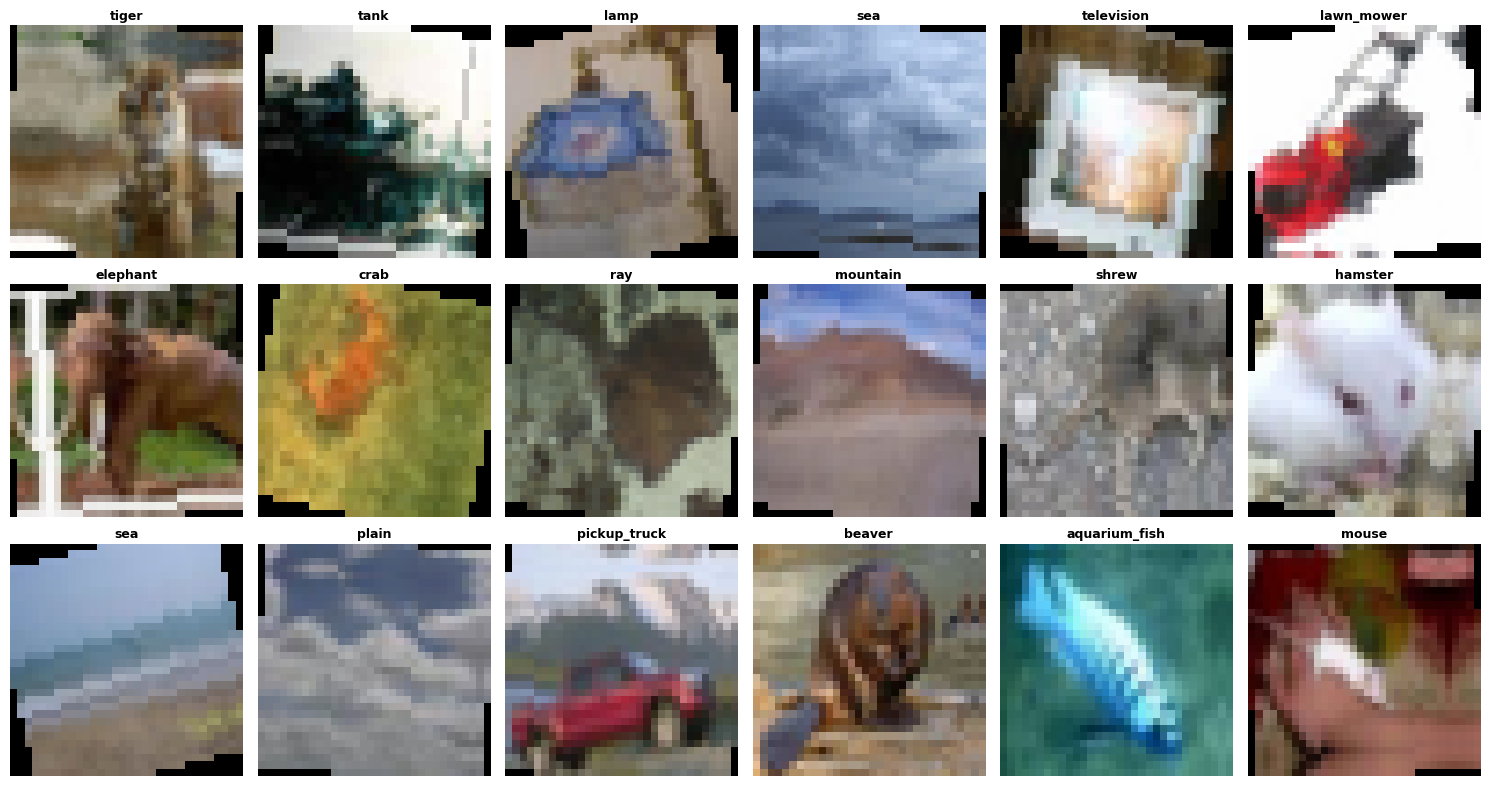

In [3]:
def imshow_grid(images, labels, classes, n_rows=3, n_cols=6):
    # Un-normalize để đưa giá trị pixel về lại [0, 1] cho hiển thị
    mean = np.array(NORM_MEAN).reshape(3, 1, 1)
    std = np.array(NORM_STD).reshape(3, 1, 1)
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 8))
    axes = axes.flatten()
    
    for i in range(n_rows * n_cols):
        img = images[i].numpy()
        img = img * std + mean
        img = np.clip(img, 0, 1)
        img = np.transpose(img, (1, 2, 0))
        
        axes[i].imshow(img)
        axes[i].set_title(classes[labels[i]], fontsize=9, fontweight='bold', pad=4)
        axes[i].axis('off')
        
    plt.tight_layout()
    plt.show()

# Lấy 1 batch thử nghiệm để trực quan
data_iter = iter(train_loader)
sample_images, sample_labels = next(data_iter)
imshow_grid(sample_images, sample_labels, classes, n_rows=3, n_cols=6)

In [4]:
import torch
import torch.nn as nn


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Điều chỉnh shortcut khi đổi số kênh hoặc kích thước ảnh
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels,
                    kernel_size=1, stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = out + identity
        return self.relu(out)


class CIFARResNet(nn.Module):
    def __init__(self, num_classes=100, blocks_per_stage=3):
        super().__init__()

        # Giữ độ phân giải 32×32 ở đầu mạng
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )

        self.stage1 = self.make_stage(
            32, 32, blocks_per_stage, stride=1
        )  # 32×32

        self.stage2 = self.make_stage(
            32, 64, blocks_per_stage, stride=2
        )  # 16×16

        self.stage3 = self.make_stage(
            64, 128, blocks_per_stage, stride=2
        )  # 8×8

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(128, num_classes),
        )

        self.initialize_weights()

    @staticmethod
    def make_stage(in_channels, out_channels, num_blocks, stride):
        layers = [
            ResidualBlock(in_channels, out_channels, stride=stride)
        ]
        for _ in range(1, num_blocks):
            layers.append(ResidualBlock(out_channels, out_channels))
        return nn.Sequential(*layers)

    def initialize_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(
                    module.weight, mode="fan_out", nonlinearity="relu"
                )
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Linear):
                nn.init.normal_(module.weight, mean=0.0, std=0.01)
                nn.init.zeros_(module.bias)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.pool(x)
        return self.classifier(x)


set_seed(42)
model = CIFARResNet(num_classes=100).to(device)

model.eval()
with torch.no_grad():
    sample_output = model(torch.randn(2, 3, 32, 32, device=device))

print("Output shape:", sample_output.shape)  # torch.Size([2, 100])
print(
    "Số tham số:",
    f"{sum(p.numel() for p in model.parameters()):,}"
)

Output shape: torch.Size([2, 100])
Số tham số: 1,096,196


In [5]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=1e-4, path='/kaggle/working/best_cifar100_resnet.pth', mode='min'):
        """
        mode: 'min' khi theo dõi val_loss, 'max' khi theo dõi val_acc
        """
        self.patience = patience
        self.min_delta = min_delta
        self.path = path
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.best_loss = np.inf if mode == 'min' else -np.inf

    def __call__(self, current_metric, model):
        score = -current_metric if self.mode == 'min' else current_metric

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(current_metric, model)
        elif score < self.best_score + self.min_delta:
            self.counter += 1
            print(f"⏳ EarlyStopping counter: {self.counter}/{self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(current_metric, model)
            self.counter = 0

    def save_checkpoint(self, metric_val, model):
        torch.save(model.state_dict(), self.path)
        self.best_loss = metric_val
        print(f"💾 Checkpoint lưu thành công! (Metric tối ưu: {metric_val:.4f})")

In [6]:
def train_one_epoch(
    model, dataloader, criterion, optimizer,
    device, epoch, total_epochs, mixup_alpha=0.2
):
    model.train()
    running_loss = 0.0
    correct = 0.0
    total = 0

    pbar = tqdm(
        dataloader,
        desc=f"Epoch [{epoch:02d}/{total_epochs:02d}] Train",
        leave=False,
    )

    for images, labels in pbar:
        images = images.to(device)
        labels = labels.to(device)

        # Trộn hai ảnh trong cùng batch
        lam = np.random.beta(mixup_alpha, mixup_alpha)
        indices = torch.randperm(images.size(0), device=device)

        mixed_images = (
            lam * images + (1.0 - lam) * images[indices]
        )
        labels_a = labels
        labels_b = labels[indices]

        optimizer.zero_grad()
        outputs = model(mixed_images)

        loss = (
            lam * criterion(outputs, labels_a)
            + (1.0 - lam) * criterion(outputs, labels_b)
        )

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        running_loss += loss.item() * batch_size

        # Chỉ số accuracy có trọng số trên ảnh MixUp
        preds = outputs.argmax(dim=1)
        correct += (
            lam * preds.eq(labels_a).sum().item()
            + (1.0 - lam) * preds.eq(labels_b).sum().item()
        )
        total += batch_size

        pbar.set_postfix({
            "loss": f"{running_loss / total:.4f}",
            "mix_acc": f"{100.0 * correct / total:.2f}%",
        })

    return running_loss / total, 100.0 * correct / total

In [7]:
@torch.no_grad()
def evaluate(
    model, dataloader, criterion,
    device, epoch=0, total_epochs=0
):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    pbar = tqdm(
        dataloader,
        desc=f"Epoch [{epoch:02d}/{total_epochs:02d}] Eval",
        leave=False,
    )

    for images, labels in pbar:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)

        pbar.set_postfix({
            "loss": f"{running_loss / total:.4f}",
            "acc": f"{100.0 * correct / total:.2f}%",
        })

    return running_loss / total, 100.0 * correct / total

In [8]:
EPOCHS = 200
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [],   'val_acc': []
}

best_val_acc = 0.0
save_path = "/kaggle/working/best_cifar100_resnet_mixup.pth"
print("🚀 Bắt đầu huấn luyện trọn vẹn 200 Epochs...")
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device, epoch, EPOCHS)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device, epoch, EPOCHS)
    scheduler.step()

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    # Chỉ lưu trọng số khi Val Acc đạt kỷ lục mới
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), save_path)
        mark = f"🔥 [KỶ LỤC MỚI: {val_acc:.2f}%]"
    else:
        mark = ""

    lr_cur = scheduler.get_last_lr()[0]
    print(f"Epoch [{epoch:03d}/{EPOCHS:03d}] (LR: {lr_cur:.5f}) | "
          f"Train: Loss {train_loss:.4f} - Acc {train_acc:.2f}% | "
          f"Val: Loss {val_loss:.4f} - Acc {val_acc:.2f}% {mark}")

total_minutes = (time.time() - start_time) / 60
print(f"\n🎉 Huấn luyện hoàn tất trong {total_minutes:.2f} phút!")
print(f"🏆 Best Validation Accuracy: {best_val_acc:.2f}%")

🚀 Bắt đầu huấn luyện trọn vẹn 200 Epochs...


Epoch [001/200] (LR: 0.09999) | Train: Loss 4.2939 - Acc 5.40% | Val: Loss 3.9842 - Acc 10.28% 🔥 [KỶ LỤC MỚI: 10.28%]


Epoch [002/200] (LR: 0.09998) | Train: Loss 4.0289 - Acc 10.38% | Val: Loss 3.7484 - Acc 14.92% 🔥 [KỶ LỤC MỚI: 14.92%]


Epoch [003/200] (LR: 0.09994) | Train: Loss 3.8539 - Acc 14.29% | Val: Loss 3.6754 - Acc 16.90% 🔥 [KỶ LỤC MỚI: 16.90%]


Epoch [004/200] (LR: 0.09990) | Train: Loss 3.6608 - Acc 18.70% | Val: Loss 3.3384 - Acc 24.20% 🔥 [KỶ LỤC MỚI: 24.20%]


...

Epoch [196/200] (LR: 0.00010) | Train: Loss 1.7944 - Acc 77.62% | Val: Loss 1.6693 - Acc 74.12% 


Epoch [197/200] (LR: 0.00006) | Train: Loss 1.7578 - Acc 78.78% | Val: Loss 1.6724 - Acc 74.30% 


Epoch [198/200] (LR: 0.00002) | Train: Loss 1.8020 - Acc 77.52% | Val: Loss 1.6621 - Acc 74.50% 🔥 [KỶ LỤC MỚI: 74.50%]


Epoch [199/200] (LR: 0.00001) | Train: Loss 1.8354 - Acc 76.60% | Val: Loss 1.6551 - Acc 74.40% 


Epoch [200/200] (LR: 0.00000) | Train: Loss 1.7371 - Acc 79.24% | Val: Loss 1.6702 - Acc 74.14% 

🎉 Huấn luyện hoàn tất trong 89.10 phút!
🏆 Best Validation Accuracy: 74.50%


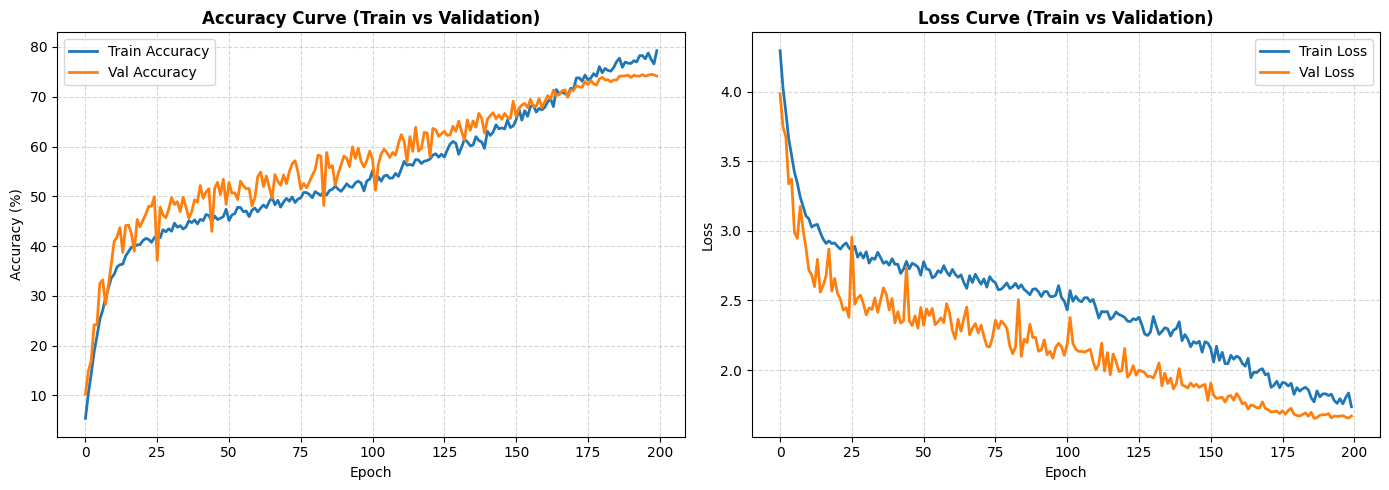


🎯 TIẾN HÀNH ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP (10,000 ẢNH)



🏆 KẾT QUẢ CUỐI CÙNG:
   -> Test Loss    : 1.6600
   -> Test Accuracy: 73.91%


In [9]:
# 1. Vẽ biểu đồ quá trình Train & Validation
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history['train_acc'], label='Train Accuracy', color='#1f77b4', lw=2)
plt.plot(history['val_acc'], label='Val Accuracy', color='#ff7f0e', lw=2)
plt.title('Accuracy Curve (Train vs Validation)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history['train_loss'], label='Train Loss', color='#1f77b4', lw=2)
plt.plot(history['val_loss'], label='Val Loss', color='#ff7f0e', lw=2)
plt.title('Loss Curve (Train vs Validation)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.savefig('/kaggle/working/train_val_curves.png', dpi=300)
plt.show()

# 2. Đánh giá chính thức trên Test Set (10.000 ảnh độc lập)
print("\n" + "="*50)
print("🎯 TIẾN HÀNH ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP (10,000 ẢNH)")
print("="*50)

# Tải trọng số tốt nhất đã được lưu từ tập Validation
model.load_state_dict(
    torch.load(
        save_path,
        map_location=device,
        weights_only=True,
    )
)
test_loss, test_acc = evaluate(model, test_loader, criterion, device, 0, 0)
print(f"\n🏆 KẾT QUẢ CUỐI CÙNG:")
print(f"   -> Test Loss    : {test_loss:.4f}")
print(f"   -> Test Accuracy: {test_acc:.2f}%")
print("="*50)

In [10]:
train_clean_loader = DataLoader(
    Subset(raw_train_clean, train_indices),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

# Chạy sau khi tải checkpoint tốt nhất
train_clean_loss, train_clean_acc = evaluate(
    model, train_clean_loader, criterion, device, 0, 0
)

print(f"Clean train accuracy: {train_clean_acc:.2f}%")

Clean train accuracy: 95.58%


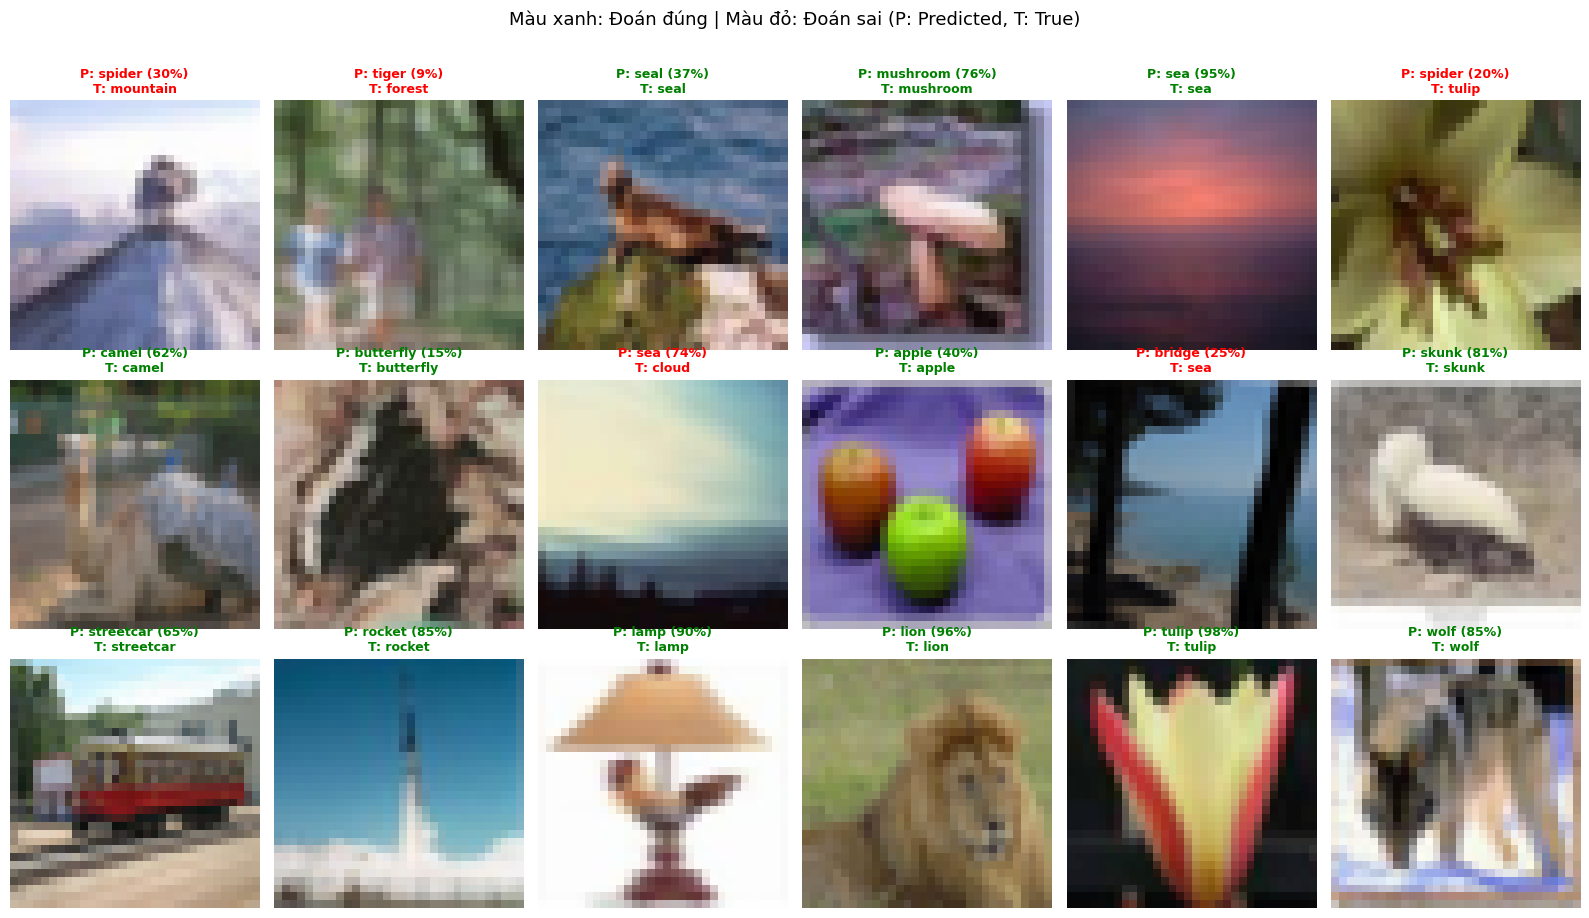

In [11]:
import torch.nn.functional as F

def visualize_predictions(model, dataloader, classes, num_images=18):
    model.eval()
    images_list, labels_list, preds_list, probs_list = [], [], [], []
    
    with torch.no_grad():
        for imgs, lbls in dataloader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model(imgs)
            probs = F.softmax(outputs, dim=1)
            confidences, preds = torch.max(probs, 1)
            
            images_list.extend(imgs.cpu())
            labels_list.extend(lbls.cpu())
            preds_list.extend(preds.cpu())
            probs_list.extend(confidences.cpu())
            
            if len(images_list) >= num_images:
                break
                
    mean = np.array(NORM_MEAN).reshape(3, 1, 1)
    std = np.array(NORM_STD).reshape(3, 1, 1)
    
    rows, cols = 3, 6
    fig, axes = plt.subplots(rows, cols, figsize=(16, 9))
    axes = axes.flatten()
    
    for i in range(num_images):
        img = images_list[i].numpy() * std + mean
        img = np.clip(img, 0, 1).transpose(1, 2, 0)
        
        true_label = classes[labels_list[i]]
        pred_label = classes[preds_list[i]]
        confidence = probs_list[i].item() * 100
        
        is_correct = (labels_list[i] == preds_list[i])
        title_color = 'green' if is_correct else 'red'
        
        axes[i].imshow(img)
        title_str = f"P: {pred_label} ({confidence:.0f}%)\nT: {true_label}"
        axes[i].set_title(title_str, fontsize=9, color=title_color, fontweight='bold')
        axes[i].axis('off')
        
    plt.suptitle("Màu xanh: Đoán đúng | Màu đỏ: Đoán sai (P: Predicted, T: True)", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()

visualize_predictions(model, test_loader, classes, num_images=18)

Đang tính toán dự đoán trên toàn bộ tập Test...


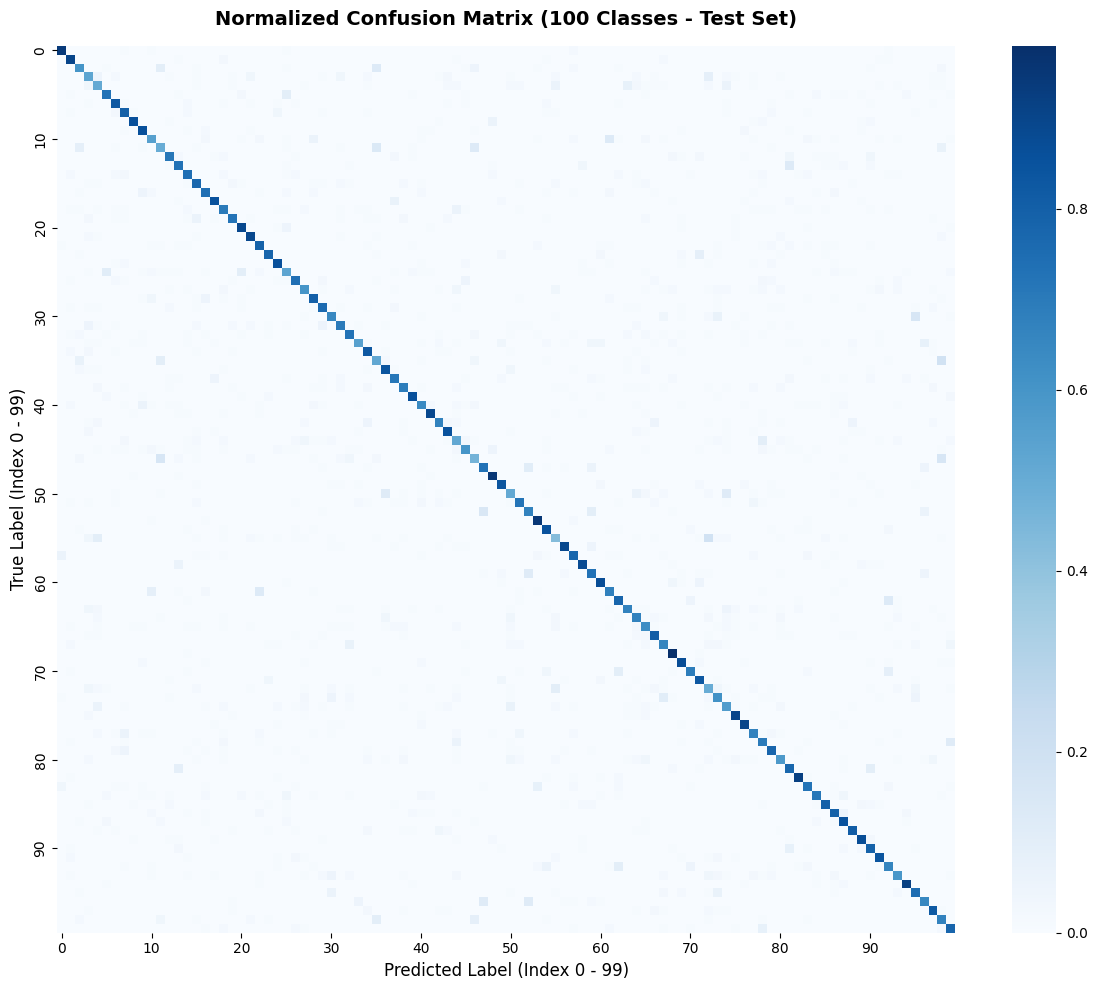

In [12]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

@torch.no_grad()
def get_all_preds(model, dataloader, device):
    model.eval()
    all_preds = []
    all_targets = []
    
    for images, labels in dataloader:
        images = images.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.numpy())
        
    return np.array(all_targets), np.array(all_preds)

print("Đang tính toán dự đoán trên toàn bộ tập Test...")
y_true, y_pred = get_all_preds(model, test_loader, device)

# 1. Tính toán confusion matrix gốc
cm = confusion_matrix(y_true, y_pred)

# 2. Chuẩn hóa theo hàng (chia cho tổng số mẫu của từng lớp thực tế)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# 3. Vẽ Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_norm, 
    cmap='Blues', 
    cbar=True,
    xticklabels=10, # Cứ cách 10 nhãn hiển thị 1 tick để không bị đè chữ
    yticklabels=10
)

plt.title('Normalized Confusion Matrix (100 Classes - Test Set)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Label (Index 0 - 99)', fontsize=12)
plt.ylabel('True Label (Index 0 - 99)', fontsize=12)

# Lưu hình ảnh chất lượng cao vào Kaggle working
plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrix.png', dpi=300)
plt.show()

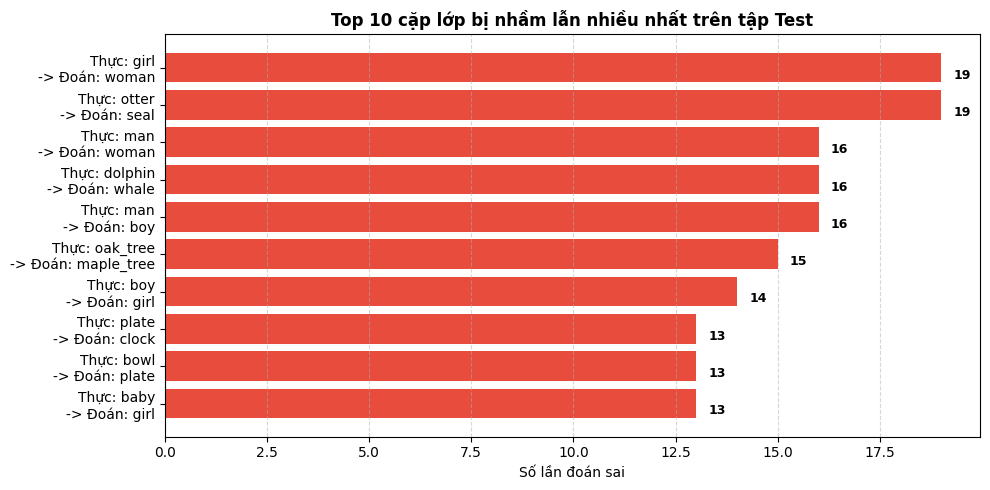

In [13]:
from collections import Counter

def plot_top_confusions(model, dataloader, classes, top_k=10):
    model.eval()
    wrong_pairs = []
    
    with torch.no_grad():
        for imgs, lbls in dataloader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model(imgs)
            _, preds = outputs.max(1)
            
            mask = preds != lbls
            wrong_true = lbls[mask].cpu().numpy()
            wrong_pred = preds[mask].cpu().numpy()
            
            for t, p in zip(wrong_true, wrong_pred):
                wrong_pairs.append((classes[t], classes[p]))
                
    counts = Counter(wrong_pairs).most_common(top_k)
    labels = [f"Thực: {t}\n-> Đoán: {p}" for (t, p), _ in counts]
    values = [val for _, val in counts]
    
    plt.figure(figsize=(10, 5))
    bars = plt.barh(labels[::-1], values[::-1], color='#e74c3c')
    plt.xlabel('Số lần đoán sai')
    plt.title(f'Top {top_k} cặp lớp bị nhầm lẫn nhiều nhất trên tập Test', fontsize=12, fontweight='bold')
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    
    for bar in bars:
        plt.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/4, 
                 f"{int(bar.get_width())}", va='center', fontsize=9, fontweight='bold')
                 
    plt.tight_layout()
    plt.show()

plot_top_confusions(model, test_loader, classes, top_k=10)